# Modern Portfolio Theory: Mathematical Optimization of Risk and Return Using Python

**Project:** Мathematical foundations, exploratory analysis, an equal-weight benchmark, and a reproducible Monte Carlo simulation of 5,000 long-only allocations.

**Research question:** *How can the allocation of capital across four technology stocks affect expected return and volatility, and can mathematical optimization improve on a simple equal-weight allocation?*

**Scope:** Long-only portfolios of four assets (AAPL, MSFT, GOOG, AMZN); fully invested weights summing to one; weekly simple returns; annualized sample moments. Estimation uses a training period; a chronologically held-out period is reserved for future evaluation.

**Important:** This is a mathematical case study, not investment advice or a claim that historical patterns predict future performance.

## 1. Objectives and scientific approach

1. State the portfolio allocation problem in mathematical terms.
2. Describe and validate the historical sample dataset.
3. Calculate weekly returns, correlations, annualized arithmetic mean returns, and annualized covariance.
4. Implement and test formulas for portfolio expected return and volatility.
5. **This iteration:** generate 5,000 random feasible allocations, compare their estimated risk–return characteristics with equal weights, and identify promising *sampled* candidates.
6. **Future iteration:** use constrained numerical optimization to solve for minimum variance and maximum Sharpe ratio, then evaluate fixed weights on held-out data.

**Working hypothesis:** Some allocations exhibit lower *estimated in-sample risk* than equal weights. A Monte Carlo search can reveal examples, but finite random sampling does not prove global optimality or out-of-sample superiority.

## 2. Data and reproducibility

We use the **Plotly sample stocks dataset** (six technology stocks, 2018–2019). The local CSV is an extracted subset of the four selected companies. The series are *normalized price indices* starting at 1, **not** USD price quotes. Percent changes of a normalized index are suitable for this exercise.

**Source:** [Plotly data documentation](https://plotly.com/python-api-reference/generated/plotly.data.html) — `plotly.data.stocks()` (also available as `plotly.express.data.stocks()`).

**Limitations:** The dataset covers a short and dated interval, consists entirely of technology stocks, and does not document whether the indices include cash dividends, transactions costs, or other real-market frictions. We therefore analyze *sample price-index returns*, not actual total investor returns.

The CSV is included with this repository; rerunning the notebook requires **no internet connection**.

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 5), "axes.grid": True, "grid.alpha": 0.25})

DATA_PATH = Path("data/stocks_normalized_2018_2019.csv")
ASSETS = ["AAPL", "MSFT", "GOOG", "AMZN"]
WEEKS_PER_YEAR = 52

In [9]:
prices = pd.read_csv(DATA_PATH, parse_dates=["date"]).set_index("date")
prices = prices[ASSETS].sort_index()

# Explicit checks keep the analysis reproducible and fail early on bad data.
assert not prices.empty
assert prices.index.is_unique and prices.index.is_monotonic_increasing
assert not prices.isna().any().any()
assert (prices > 0).all().all()
assert prices.shape[0] >= 100

print(f"Observations: {len(prices)}")
print(f"From: {prices.index.min().date()} to {prices.index.max().date()}")
display(prices.head())

Observations: 105
From: 2018-01-01 to 2019-12-30


,AAPL,MSFT,GOOG,AMZN
date,,,,
2018-01-01,1.000000,1.000000,1.000000,1.000000
2018-01-08,1.011943,1.015988,1.018172,1.061881
2018-01-15,1.019771,1.020524,1.032008,1.053240
2018-01-22,0.980057,1.066561,1.066783,1.140676
2018-01-29,0.917143,1.040708,1.008773,1.163374


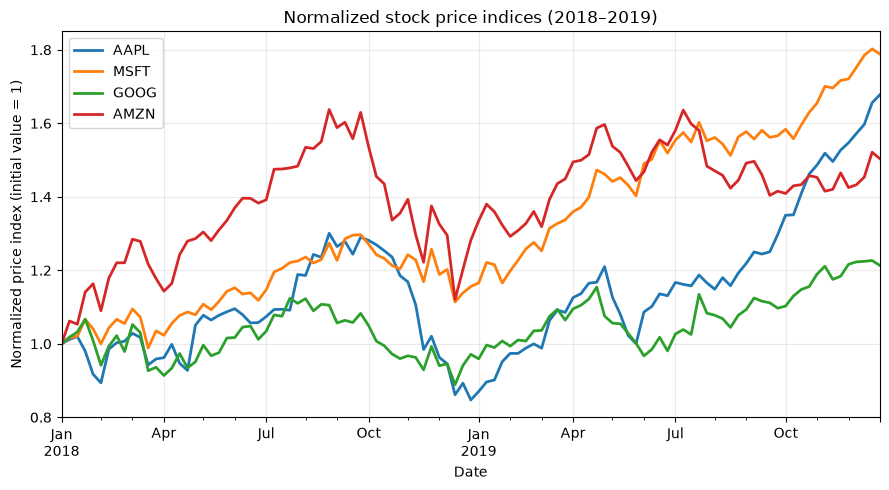

In [10]:
ax = prices.plot(linewidth=2, title="Normalized stock price indices (2018–2019)")
ax.set_ylabel("Normalized price index (initial value = 1)")
ax.set_xlabel("Date")
plt.tight_layout()
plt.show()

## 3. Mathematical background

Let $P_{i,t}$ be the normalized index value for stock $i$ at week $t$. Its **weekly simple return** is

$$r_{i,t}=\frac{P_{i,t}}{P_{i,t-1}}-1.$$

For $n=4$ assets, the portfolio weight vector is $\mathbf{w}=(w_1,\dots,w_4)^T$ with long-only, fully invested constraints

$$\sum_{i=1}^4 w_i=1, \qquad 0\le w_i\le 1.$$

The estimated **annualized arithmetic expected return** and **annualized covariance matrix** are

$$\boldsymbol{\hat\mu}_{ann}=52\,\overline{\mathbf r}_{weekly}, \qquad \hat\Sigma_{ann}=52\,\widehat{\mathrm{Cov}}(\mathbf r_{weekly}).$$

The corresponding estimated portfolio expected return and volatility are

$$\hat\mu_p=\mathbf w^T\boldsymbol{\hat\mu}_{ann}, \qquad
\hat\sigma_p=\sqrt{\mathbf w^T\hat\Sigma_{ann}\mathbf w}.$$

The square-root in the final expression converts **variance** into **standard deviation**. This is the mean-variance portfolio framework discussed by Markowitz (1952). For weekly observations, the factor of 52 is an approximation based on stationarity and standard aggregation assumptions. Annualized arithmetic mean return is **not** the same as realized compounded annual return.

In [11]:
weekly_returns = prices.pct_change().dropna()
assert len(weekly_returns) == len(prices) - 1
assert np.isfinite(weekly_returns.to_numpy()).all()

# Chronological split: reserve the last 30% for later out-of-sample evaluation.
split_at = int(len(weekly_returns) * 0.70)
train_returns = weekly_returns.iloc[:split_at].copy()
test_returns = weekly_returns.iloc[split_at:].copy()
assert train_returns.index.max() < test_returns.index.min()

annual_mean = train_returns.mean() * WEEKS_PER_YEAR
annual_cov = train_returns.cov() * WEEKS_PER_YEAR
annual_volatility = train_returns.std(ddof=1) * np.sqrt(WEEKS_PER_YEAR)

summary = pd.DataFrame({
    "Annualized arithmetic mean": annual_mean,
    "Annualized volatility": annual_volatility,
})
print(f"Training weeks: {len(train_returns)}; held-out weeks: {len(test_returns)}")
display(summary.style.format("{:.2%}"))

Training weeks: 72; held-out weeks: 32


,Annualized arithmetic mean,Annualized volatility
AAPL,6.05%,30.03%
MSFT,28.15%,21.00%
GOOG,5.10%,24.89%
AMZN,33.22%,30.72%


## 4. Diversification and covariance

Diversification is not solely about the number of assets; it depends on how their returns co-move. Correlation near +1 implies limited diversification benefit, while lower correlations can reduce portfolio variance for a fixed set of weights. These four technology companies are not a broad representation of the market.

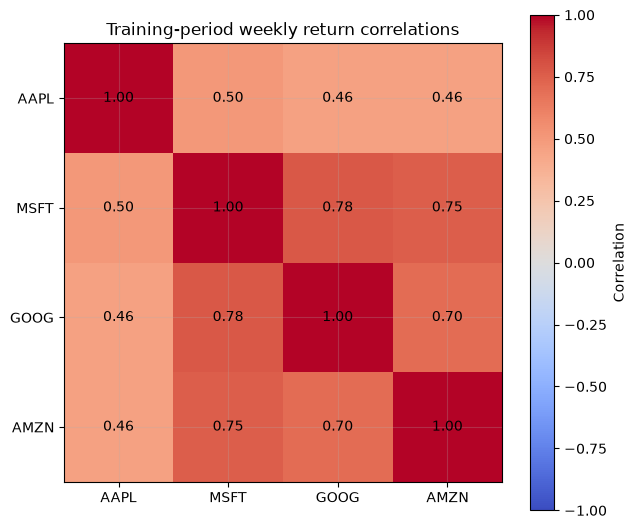

In [12]:
correlation = train_returns.corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(correlation.to_numpy(), vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(ASSETS)), ASSETS)
ax.set_yticks(range(len(ASSETS)), ASSETS)
for i in range(len(ASSETS)):
    for j in range(len(ASSETS)):
        ax.text(j, i, f"{correlation.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Training-period weekly return correlations")
fig.tight_layout()
plt.show()

## 5. Equal-weight benchmark and validation

A neutral baseline assigns 25% to each of the four assets. It is **not** necessarily the lowest-risk or highest-return allocation. Implementing the formulas from Section 3 provides a testable benchmark for later numerical optimization.

In [13]:
def portfolio_statistics(weights: np.ndarray,
                         expected_returns: pd.Series,
                         covariance: pd.DataFrame) -> tuple[float, float]:
    """Return annualized arithmetic expected return and volatility.

    Parameters
    ----------
    weights : array of shape (n_assets,)
        Non-negative portfolio fractions summing to one.
    expected_returns : Series
        Estimated annualized arithmetic asset returns.
    covariance : DataFrame
        Estimated annualized asset return covariance matrix.
    """
    w = np.asarray(weights, dtype=float)
    mu = expected_returns.to_numpy(dtype=float)
    sigma = covariance.to_numpy(dtype=float)
    if w.ndim != 1 or w.size != len(mu) or sigma.shape != (w.size, w.size):
        raise ValueError("Incompatible vector or covariance dimensions")
    if not np.isclose(w.sum(), 1.0, atol=1e-8) or np.any(w < -1e-10):
        raise ValueError("Weights must be non-negative and sum to 1")

    expected_return = float(w @ mu)
    variance = float(w @ sigma @ w)
    volatility = float(np.sqrt(max(variance, 0.0)))  # protect against rounding
    return expected_return, volatility


weights_equal = np.full(len(ASSETS), 1 / len(ASSETS))
equal_return, equal_volatility = portfolio_statistics(weights_equal, annual_mean, annual_cov)
print("Equal-weight allocation:", dict(zip(ASSETS, weights_equal)))
print(f"Estimated annualized arithmetic return: {equal_return:.2%}")
print(f"Estimated annualized volatility:       {equal_volatility:.2%}")

Equal-weight allocation: {'AAPL': np.float64(0.25), 'MSFT': np.float64(0.25), 'GOOG': np.float64(0.25), 'AMZN': np.float64(0.25)}
Estimated annualized arithmetic return: 18.13%
Estimated annualized volatility:       22.25%


In [14]:
# Mathematical checks: a 100% allocation to one asset must reproduce
# that asset's expected return and volatility.
for i, asset in enumerate(ASSETS):
    single_asset_weights = np.eye(len(ASSETS))[i]
    r, v = portfolio_statistics(single_asset_weights, annual_mean, annual_cov)
    assert np.isclose(r, annual_mean[asset], rtol=1e-10)
    assert np.isclose(v, annual_volatility[asset], rtol=1e-10)

assert np.allclose(annual_cov, annual_cov.T)
assert np.linalg.eigvalsh(annual_cov.to_numpy()).min() > -1e-10
print("All portfolio formula checks passed.")

All portfolio formula checks passed.


## 6. Monte Carlo simulation of 5,000 feasible portfolios

### Motivation and mathematical method

Instead of choosing portfolio weights arbitrarily, we sample many feasible allocations and evaluate each under the same historical estimates of mean return and covariance. This is a **Monte Carlo search over weights**, not a simulation of future stock prices or portfolio outcomes.

For every sampled portfolio $k$, we calculate

$$\widehat\mu_p^{(k)} = (\mathbf w^{(k)})^T \widehat{\boldsymbol\mu}_{ann},$$

$$\widehat\sigma_p^{(k)} = \sqrt{(\mathbf w^{(k)})^T\widehat\Sigma_{ann}\mathbf w^{(k)}}.$$

We draw $\mathbf w^{(k)} \sim \mathrm{Dirichlet}(1,1,1,1)$. This distribution yields nonnegative components summing to one and is uniform with respect to volume on the four-asset weight simplex. It does **not** guarantee that the best sampled point is a true mathematical optimum.

For comparative visualization, define an *illustrative* assumed risk-free annual rate $r_f=2\%$, and compute the estimated Sharpe ratio

$$\widehat S_p^{(k)} = \frac{\widehat\mu_p^{(k)} - r_f}{\widehat\sigma_p^{(k)}}.$$

The 2% rate is a **modeling assumption** used consistently in the comparison, not a historically verified risk-free yield. Arithmetic sample mean, sample covariance, and volatility remain fixed for all candidate portfolios, estimated **only from training observations**.

In [15]:
# Reproducible random search (sampling portfolio weights, NOT future prices).
N_PORTFOLIOS = 5_000
RANDOM_SEED = 42
ASSUMED_RISK_FREE_RATE = 0.02  # annualized, hypothetical

rng = np.random.default_rng(RANDOM_SEED)
random_weights = rng.dirichlet(np.ones(len(ASSETS)), size=N_PORTFOLIOS)

# All simulated portfolios satisfy the long-only, fully invested constraints.
assert random_weights.shape == (N_PORTFOLIOS, len(ASSETS))
assert np.all(random_weights >= 0.0)
assert np.allclose(random_weights.sum(axis=1), 1.0, atol=1e-12)
assert np.allclose(
    random_weights[:3],
    np.random.default_rng(RANDOM_SEED).dirichlet(np.ones(len(ASSETS)), size=3),
)

mean_vector = annual_mean.to_numpy(dtype=float)
covariance_matrix = annual_cov.to_numpy(dtype=float)

# Vectorized versions of w.T @ mu and sqrt(w.T @ Sigma @ w).
simulated_returns = random_weights @ mean_vector
simulated_variances = np.einsum(
    "ij,jk,ik->i", random_weights, covariance_matrix, random_weights
)
simulated_volatilities = np.sqrt(np.maximum(simulated_variances, 0.0))
assert np.all(simulated_volatilities > 0)
simulated_sharpe = (
    simulated_returns - ASSUMED_RISK_FREE_RATE
) / simulated_volatilities

# Verify the vectorized computation against the earlier single-portfolio function.
for i in range(10):
    r, v = portfolio_statistics(random_weights[i], annual_mean, annual_cov)
    assert np.isclose(simulated_returns[i], r, rtol=1e-12)
    assert np.isclose(simulated_volatilities[i], v, rtol=1e-12)

simulated = pd.DataFrame(random_weights, columns=[f"weight_{a}" for a in ASSETS])
simulated["expected_return"] = simulated_returns
simulated["volatility"] = simulated_volatilities
simulated["sharpe"] = simulated_sharpe

print(f"Generated and validated {len(simulated):,} feasible portfolios.")
display(simulated.head().round(4))

Generated and validated 5,000 feasible portfolios.


,weight_AAPL,weight_MSFT,weight_GOOG,weight_AMZN,expected_return,volatility,sharpe
0,0.3247,0.3155,0.3220,0.0378,0.1374,0.2142,0.5482
1,0.0142,0.2392,0.2322,0.5144,0.2510,0.2472,0.9343
2,0.0347,0.4580,0.0308,0.4765,0.2909,0.2393,1.1321
3,0.4942,0.1104,0.3515,0.0439,0.0935,0.2300,0.3195
4,0.0532,0.1831,0.5237,0.2400,0.1612,0.2307,0.6122


### Representative portfolios from the simulation

We identify two *best observed among the 5,000 random candidates*:

- **Lowest sampled volatility:** the candidate with minimum $\widehat\sigma_p$.
- **Highest sampled Sharpe ratio:** the candidate with maximum $\widehat S_p$.

We compare both against the fixed **25%-per-asset equal-weight portfolio**. None of these estimates represents a guaranteed future performance. In particular, random search is not yet a formal constrained optimizer.

In [16]:
index_min_vol = int(np.argmin(simulated_volatilities))
index_max_sharpe = int(np.argmax(simulated_sharpe))

def candidate_summary(label: str, weights: np.ndarray) -> dict:
    expected_return, volatility = portfolio_statistics(weights, annual_mean, annual_cov)
    result = {
        "Portfolio": label,
        "Expected return": expected_return,
        "Volatility": volatility,
        "Sharpe (rf=2%)": (expected_return - ASSUMED_RISK_FREE_RATE) / volatility,
    }
    result.update({f"{asset} weight": weight for asset, weight in zip(ASSETS, weights)})
    return result

candidate_weights = {
    "Equal weight": weights_equal,
    "Lowest sampled volatility": random_weights[index_min_vol],
    "Highest sampled Sharpe": random_weights[index_max_sharpe],
}
comparison = pd.DataFrame(
    [candidate_summary(name, weights) for name, weights in candidate_weights.items()]
).set_index("Portfolio")

# Display percentages and a dimensionless Sharpe ratio separately.
formatters = {name: "{:.2%}" for name in comparison.columns if name != "Sharpe (rf=2%)"}
formatters["Sharpe (rf=2%)"] = "{:.3f}"
display(comparison.style.format(formatters))

print("For this fixed random seed and training dataset:")
for name in ["Lowest sampled volatility", "Highest sampled Sharpe"]:
    row = comparison.loc[name]
    print(f"{name}: return = {row['Expected return']:.2%}, "
          f"volatility = {row['Volatility']:.2%}, Sharpe = {row['Sharpe (rf=2%)']:.3f}")

assert comparison.loc["Lowest sampled volatility", "Volatility"] <= comparison.loc["Equal weight", "Volatility"]
assert comparison.loc["Highest sampled Sharpe", "Sharpe (rf=2%)"] >= comparison.loc["Equal weight", "Sharpe (rf=2%)"]

,Expected return,Volatility,Sharpe (rf=2%),AAPL weight,MSFT weight,GOOG weight,AMZN weight
Portfolio,,,,,,,
Equal weight,18.13%,22.25%,0.725,25.00%,25.00%,25.00%,25.00%
Lowest sampled volatility,21.27%,20.45%,0.943,14.69%,69.23%,15.81%,0.27%
Highest sampled Sharpe,28.42%,21.30%,1.240,0.12%,88.63%,0.98%,10.27%


For this fixed random seed and training dataset:
Lowest sampled volatility: return = 21.27%, volatility = 20.45%, Sharpe = 0.943
Highest sampled Sharpe: return = 28.42%, volatility = 21.30%, Sharpe = 1.240


### Visualizing the risk–return trade-off

Each point below is one random feasible portfolio, positioned using **training-period estimates**. Color represents its estimated Sharpe ratio under the hypothetical 2% annual risk-free assumption. The **simulation cloud is not the analytical efficient frontier**; we will compute constrained optima in the next part.

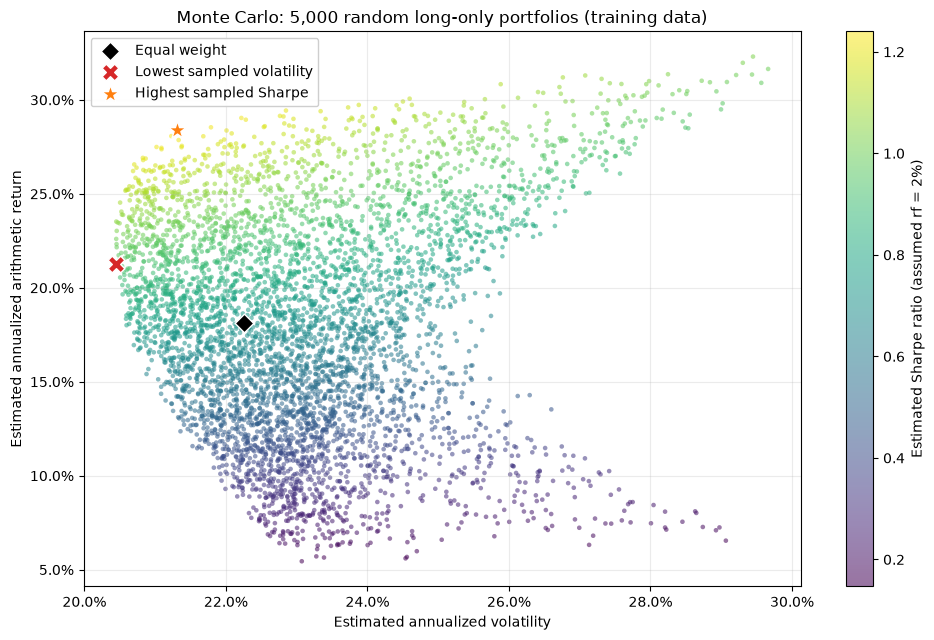

Saved plot: figures\monte_carlo_risk_return.png


In [17]:
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(10, 6.5))
scatter = ax.scatter(
    simulated_volatilities, simulated_returns,
    c=simulated_sharpe, cmap="viridis", s=11, alpha=0.55,
    linewidths=0, rasterized=True
)

markers = [
    ("Equal weight", "D", "black", 90),
    ("Lowest sampled volatility", "X", "tab:red", 145),
    ("Highest sampled Sharpe", "*", "tab:orange", 180),
]
for label, marker, color, size in markers:
    point = comparison.loc[label]
    ax.scatter(
        point["Volatility"], point["Expected return"],
        marker=marker, s=size, facecolor=color, edgecolor="white",
        linewidth=1.0, label=label, zorder=5
    )

ax.set_title("Monte Carlo: 5,000 random long-only portfolios (training data)")
ax.set_xlabel("Estimated annualized volatility")
ax.set_ylabel("Estimated annualized arithmetic return")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend(loc="best", framealpha=0.95)
fig.colorbar(scatter, ax=ax, label="Estimated Sharpe ratio (assumed rf = 2%)")
fig.tight_layout()

# A local figure is convenient for including in README or a report.
from pathlib import Path
figure_path = Path("figures/monte_carlo_risk_return.png")
figure_path.parent.mkdir(exist_ok=True)
fig.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved plot: {figure_path}")

## 7. Interpretation, limitations, and next steps

### What the Monte Carlo experiment does establish

1. The **long-only, fully invested** feasible set contains many different combinations of estimated risk and return, even with the same four assets and the same underlying sample statistics.
2. For this specific training period, among the **5,000 random allocations**, some have lower estimated volatility than the equal-weight benchmark; others have higher estimated Sharpe ratio.
3. The three highlighted portfolios can be quantitatively compared through their allocations, expected arithmetic return, volatility, and assumed-rate Sharpe ratio.
4. All candidate weights were evaluated exclusively on the **training split**; the held-out observations were not used to select them.

### What remains uncertain

- The candidates are best **among sampled random points** only; they are not necessarily global minimum-variance or maximum-Sharpe portfolios.
- The data span only 2018–2019 and four technology companies, so estimates are fragile and sector-concentrated.
- We use historical normalized price indices, and whether dividend distributions are included is not established.
- The assumed 2% risk-free rate is illustrative; transaction costs, taxes, market frictions, and real rebalancing policies are omitted.
- Annualizing historical weekly moments assumes a stable process and does not forecast the realized compounded annual return.
- We have **not** evaluated these selected weights out of sample. A better in-sample estimated trade-off need not persist in the held-out data.

### Next iteration

Implement constrained optimization using SciPy SLSQP, including convergence and constraint checks. Compare the exact numerical optimizer results with these sampled candidates and equal weights. Finally, evaluate the preselected weights on the chronological test split without refitting on test observations.

## References

1. Markowitz, H. (1952). *Portfolio Selection*. *The Journal of Finance*, 7(1), 77–91. https://doi.org/10.1111/j.1540-6261.1952.tb01525.x
2. Plotly. *plotly.data.stocks* documentation (normalized price indices for six technology stocks, 2018–2019): https://plotly.com/python-api-reference/generated/plotly.data.html
3. NumPy. *Random Generator.dirichlet* documentation: https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.dirichlet.html
4. SciPy. *minimize(method='SLSQP')* documentation: https://docs.scipy.org/doc/scipy/reference/optimize.minimize-slsqp.html